>Implementar una función que calcule las componentes principales de un conjunto de datos a partir de su descomposici ́on en valores singulares (SVD). Para el calculo de las matrices de valores singulares pueden usar las bibliotecas y módulos ya conocidos

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('./europe.csv', delimiter=',')
df.head()

,Country,Area,GDP,Inflation,Life.expect,Military,Pop.growth,Unemployment
0,Austria,83871,41600,3.5,79.91,0.80,0.03,4.2
1,Belgium,30528,37800,3.5,79.65,1.30,0.06,7.2
2,Bulgaria,110879,13800,4.2,73.84,2.60,-0.80,9.6
3,Croatia,56594,18000,2.3,75.99,2.39,-0.09,17.7
4,Czech Republic,78867,27100,1.9,77.38,1.15,-0.13,8.5


In [3]:
id = 'Country'
features = [c for c in df.columns if c != id]
X = df[features].to_numpy()

Voy a escalar el dataframe por comodidad. Podría no hacerlo y ver qué pasa

In [4]:
from sklearn.preprocessing import StandardScaler
std_scale = StandardScaler()
std_scale.fit(X)
X_scaled = std_scale.transform(X)

algoritmo PCA:
* centrar X
* Hacer SVD
* Calcular varianza por componente  y varianza total
* Calcular proporción de varianza explicada por componente
* Truncar matrices
* Proyectar X centrado sobre matrices calculadas
* Devolver $X_{proyectado}$ en $q$ componentes, $V_q^t$ (matriz de $q$ componentes principales), array con cantidad de varianza explicada por componente

In [5]:
from numpy import ndarray
def pca_svd(X:ndarray, n_componentes:int|None=None):
    X_bar = np.mean(X, axis=0)
    X_centrado = X - X_bar
    N = X.shape[0]
    
    #obs: d es un array
    U, d, Vt = np.linalg.svd(X_centrado, full_matrices=False)

    #varianza explicada
    sigma_cuad = (d ** 2) / (N - 1)
    var_total = np.sum(sigma_cuad)
    varianza_explicada_ratio = sigma_cuad / var_total

    if n_componentes is None:
        n_componentes = X.shape[1]
    #truncar a las primeras q dimensiones
    U_q = U[:, :n_componentes]
    D_q = np.diag(d[:n_componentes])
    Vt_q = Vt[:n_componentes, :]
    
    #calcular los lambda_ij = U_q * D_q
    X_proyectado = np.dot(U_q, D_q)  
    #se podría calcular de la misma forma X_proyectado = X_centrado @ Vt_q.T

    return X_proyectado, Vt_q, varianza_explicada_ratio[:n_componentes]

X_proyectado, componentes, varianza_explicada = pca_svd(X_scaled)

Grafiquitos ↓

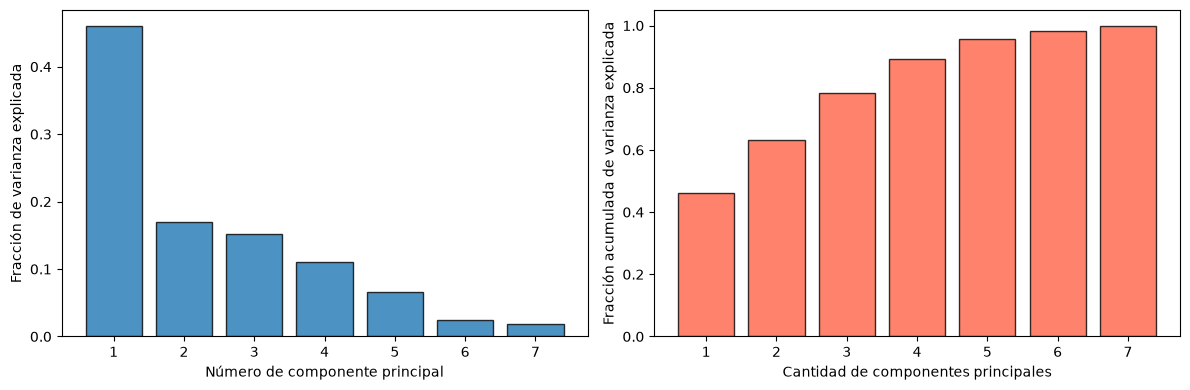

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Eje X común (número de componentes)
n_componentes = range(1, len(varianza_explicada) + 1)

# 1. Gráfico de varianza explicada individual
ax[0].bar(n_componentes, varianza_explicada, edgecolor='black', alpha=0.8)
ax[0].set_ylabel('Fracción de varianza explicada')
ax[0].set_xlabel('Número de componente principal')
ax[0].set_xticks(n_componentes) # Para asegurar que muestre cada número entero

# Varianza acumulada
varianza_acumulada = np.cumsum(varianza_explicada)

# 2. Gráfico de varianza acumulada
ax[1].bar(n_componentes, varianza_acumulada, color = 'tomato',edgecolor='black', alpha=0.8)
ax[1].set_ylabel('Fracción acumulada de varianza explicada')
ax[1].set_xlabel('Cantidad de componentes principales')
ax[1].set_xticks(n_componentes)

plt.tight_layout()
plt.show()

Composición de las componentes en función de las features originales

In [7]:
print(f'Features = {features}')
print(f'Comp. Principal 1 = {[round(float(a), 3) for a in componentes[0]]}')
print(f'Comp. Principal 2 = {[round(float(a), 3) for a in componentes[1]]}')
print(f'Comp. Principal 3 = {[round(float(a), 3) for a in componentes[2]]}')
print(f'Comp. Principal 4 = {[round(float(a), 3) for a in componentes[3]]}')

Features = ['Area', 'GDP', 'Inflation', 'Life.expect', 'Military', 'Pop.growth', 'Unemployment']
Comp. Principal 1 = [0.125, -0.501, 0.407, -0.483, 0.188, -0.476, 0.272]
Comp. Principal 2 = [0.173, 0.13, 0.37, -0.265, -0.658, -0.083, -0.553]
Comp. Principal 3 = [-0.898, -0.084, -0.198, -0.246, -0.244, -0.164, -0.001]
Comp. Principal 4 = [0.045, -0.084, 0.165, 0.027, -0.562, 0.392, 0.702]


Proyeccion de features en el espacio de componentes principales

Text(0, 0.5, 'Segunda componente principal')

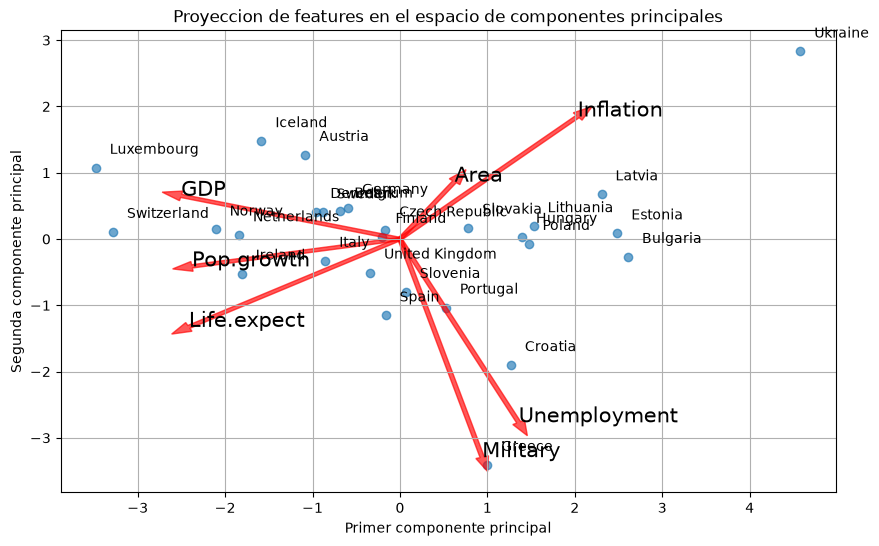

In [8]:
fig, ax = plt.subplots(figsize = (10, 6))
plt.grid()
plt.title('Proyeccion de features en el espacio de componentes principales')
for i, row in df.iterrows():
  pais = row[id]
  ax.annotate(pais, (X_proyectado[i,0],X_proyectado[i,1]), xytext=(10,10), textcoords='offset points')

ax.scatter(X_proyectado[:,0], X_proyectado[:,1], alpha = 0.65)
escala = 5
for i in range(len(features)):

  # Creamos una flecha que vaya del origen y apunte en la dirección de los features
  ax.arrow(0, 0, escala * componentes[0][i], escala * componentes[1][i], width = 0.05, color = 'r', alpha = 0.65)

  # Indicamos con texto a qué feature corresponde cada flecha
  ax.text(escala * componentes[0][i], escala * componentes[1][i], s = features[i], fontdict= {'color': 'k', 'size': 15})
ax.set_xlabel('Primer componente principal')
ax.set_ylabel('Segunda componente principal')


Comparación: PCA con los datos estandarizados vs. sin estandarizar

Repito el mismo análisis pero pasándole a `pca_svd` la matriz `X` original (la función igual centra los datos, así que la única diferencia es la escala de cada variable).

In [9]:
X_proyectado_raw, componentes_raw, varianza_explicada_raw = pca_svd(X)

print(f'Features = {features}')
print(f'Varianza por feature (sin estandarizar) = {[f"{v:.3g}" for v in X.var(axis=0, ddof=1)]}')
print(f'Comp. Principal 1 = {[round(float(a), 3) for a in componentes_raw[0]]}')
print(f'Comp. Principal 2 = {[round(float(a), 3) for a in componentes_raw[1]]}')
print(f'Varianza explicada (estandarizado)    = {np.round(varianza_explicada[:3], 3)}')
print(f'Varianza explicada (sin estandarizar) = {np.round(varianza_explicada_raw[:3], 3)}')

Features = ['Area', 'GDP', 'Inflation', 'Life.expect', 'Military', 'Pop.growth', 'Unemployment']
Varianza por feature (sin estandarizar) = ['2.74e+10', '2.1e+08', '1.96', '10.2', '0.642', '0.252', '21.9']
Comp. Principal 1 = [1.0, -0.012, 0.0, -0.0, 0.0, -0.0, 0.0]
Comp. Principal 2 = [0.012, 1.0, -0.0, 0.0, -0.0, 0.0, -0.0]
Varianza explicada (estandarizado)    = [0.461 0.17  0.152]
Varianza explicada (sin estandarizar) = [0.993 0.007 0.   ]


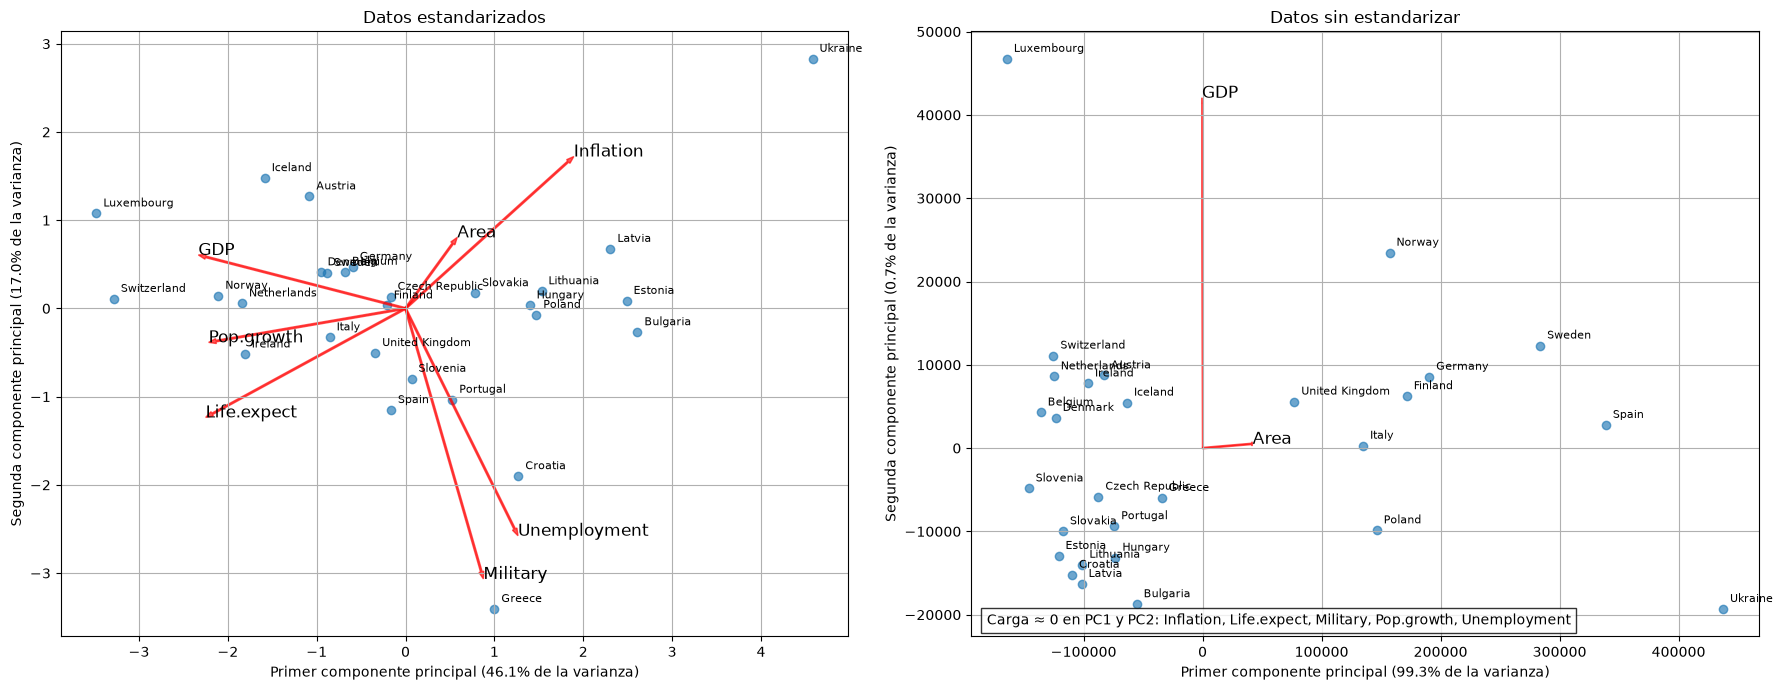

In [10]:
def biplot(ax, X_proy, comps, var_exp, titulo):
    ax.grid()
    ax.set_title(titulo)
    ax.scatter(X_proy[:, 0], X_proy[:, 1], alpha=0.65)
    for i, row in df.iterrows():
        ax.annotate(row[id], (X_proy[i, 0], X_proy[i, 1]), xytext=(5, 5), textcoords='offset points', fontsize=8)

    # Escala de las flechas relativa al rango de los datos proyectados, para que
    # entren en el gráfico en ambos casos (las escalas son muy distintas)
    escala = 0.9 * min(np.abs(X_proy[:, k]).max() / np.abs(comps[k]).max() for k in range(2))
    despreciables = []
    for i in range(len(features)):
        # Las features con carga casi nula en ambas componentes no se dibujan (quedarían todas encimadas en el origen)
        if np.hypot(comps[0][i], comps[1][i]) < 0.05:
            despreciables.append(features[i])
            continue
        ax.arrow(0, 0, escala * comps[0][i], escala * comps[1][i], color='r', alpha=0.65,
                 width=0.004 * escala, length_includes_head=True)
        ax.text(escala * comps[0][i], escala * comps[1][i], s=features[i], fontdict={'color': 'k', 'size': 12})
    if despreciables:
        ax.text(0.02, 0.02, 'Carga ≈ 0 en PC1 y PC2: ' + ', '.join(despreciables), transform=ax.transAxes,
                fontsize=10, bbox={'facecolor': 'white', 'alpha': 0.8})
    ax.set_xlabel(f'Primer componente principal ({var_exp[0]:.1%} de la varianza)')
    ax.set_ylabel(f'Segunda componente principal ({var_exp[1]:.1%} de la varianza)')

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
biplot(ax[0], X_proyectado, componentes, varianza_explicada, 'Datos estandarizados')
biplot(ax[1], X_proyectado_raw, componentes_raw, varianza_explicada_raw, 'Datos sin estandarizar')
plt.tight_layout()
plt.show()

Sin estandarizar, PCA queda dominado por las variables con mayor varianza en sus unidades originales: `Area` (varianza ~$10^{10}$, en km²) y `GDP` (~$10^{8}$). La PC1 es prácticamente `Area` sola (99.3% de la varianza) y la PC2 es `GDP`; el resto de las features tiene carga ≈ 0, así que el gráfico solo ordena a los países por superficie y PBI per cápita.

Al estandarizar, todas las variables pesan lo mismo y las componentes reflejan la estructura de correlación: la PC1 opone `GDP`, `Life.expect` y `Pop.growth` a `Inflation` y `Unemployment`, y la varianza queda más repartida (46%, 17%, 15%). Como las features están en unidades distintas, tiene sentido estandarizar.